In [1]:
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing()

print(housing.data.shape, housing.target.shape)

(20640, 8) (20640,)


In [5]:
import pandas as pd

df = pd.DataFrame(housing.data, columns=housing.feature_names)
df["Price"] = housing.target

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [6]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   Price       20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Missing values:
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
Price         0
dtype: int64

Statistical summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [ ]:
X = df.drop("Price", axis=1)
y = df["Price"]

print("Input features:", X.shape)
print("Target values:", y.shape)

Input features: (20640, 8)
Target values: (20640,)


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 16512
Testing samples: 4128


In [9]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [10]:
#Make predictions and evaluate the mode
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = model.predict(X_test)

print("MAE:", round(mean_absolute_error(y_test, y_pred), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 3))
print("R² Score:", round(r2_score(y_test, y_pred), 3))

MAE: 0.533
RMSE: 0.746
R² Score: 0.576


In [11]:
#actual vs predicted
comparison = pd.DataFrame({
    "Actual Price": y_test.values[:10],
    "Predicted Price": y_pred[:10]
})

comparison["Actual ($)"] = comparison["Actual Price"] * 100000
comparison["Predicted ($)"] = comparison["Predicted Price"] * 100000

display(comparison.round(2))

,Actual Price,Predicted Price,Actual ($),Predicted ($)
0,0.48,0.72,47700.0,71912.28
1,0.46,1.76,45800.0,176401.66
2,5.00,2.71,500001.0,270965.88
3,2.19,2.84,218600.0,283892.59
4,2.78,2.60,278000.0,260465.73
5,1.59,2.01,158700.0,201175.37
6,1.98,2.65,198200.0,264550.00
7,1.58,2.17,157500.0,216875.53
8,3.40,2.74,340000.0,274074.64
9,4.47,3.92,446600.0,391561.47


CHECKING GRADIENT BOOSTING IF THAT SUITS BETTER

In [12]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

gbr = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.1,
    max_leaf_nodes=15,
    random_state=42
)

gbr.fit(X_train, y_train)

y_pred_gbr = gbr.predict(X_test)

print("Gradient Boosting Results")
print("MAE:", mean_absolute_error(y_test, y_pred_gbr))
print("RMSE:", mean_squared_error(y_test, y_pred_gbr) ** 0.5)
print("R² Score:", r2_score(y_test, y_pred_gbr))

Gradient Boosting Results
MAE: 0.3136997415117152
RMSE: 0.4652021066108255
R² Score: 0.8348507957525872


In [14]:
#actual vs predicted
comparison = pd.DataFrame({
    "Actual Price": y_test.values[:10],
    "Predicted Price": y_pred_gbr[:10]
})

comparison["Actual ($)"] = comparison["Actual Price"] * 100000
comparison["Predicted ($)"] = comparison["Predicted Price"] * 100000

display(comparison.round(2))

,Actual Price,Predicted Price,Actual ($),Predicted ($)
0,0.48,0.60,47700.0,60036.79
1,0.46,0.88,45800.0,87931.48
2,5.00,4.67,500001.0,466956.42
3,2.19,2.46,218600.0,245888.79
4,2.78,2.43,278000.0,243410.36
5,1.59,1.66,158700.0,166326.20
6,1.98,2.23,198200.0,223041.68
7,1.58,1.60,157500.0,159858.43
8,3.40,2.62,340000.0,261991.72
9,4.47,4.71,446600.0,470954.60


Sample predictions:
       Actual  Predicted  Error  Absolute_Error
20046   0.477      0.600 -0.123           0.123
3024    0.458      0.879 -0.421           0.421
15663   5.000      4.670  0.330           0.330
20484   2.186      2.459 -0.273           0.273
9814    2.780      2.434  0.346           0.346
13311   1.587      1.663 -0.076           0.076
7113    1.982      2.230 -0.248           0.248
7668    1.575      1.599 -0.024           0.024
18246   3.400      2.620  0.780           0.780
5723    4.466      4.710 -0.244           0.244

10 worst predictions:
       Actual  Predicted  Error  Absolute_Error
19542   4.500      1.137  3.363           3.363
12389   5.000      1.873  3.127           3.127
6688    5.000      2.073  2.927           2.927
12069   5.000      2.316  2.684           2.684
10574   5.000      2.339  2.661           2.661
20325   5.000      2.381  2.619           2.619
459     5.000      2.395  2.605           2.605
5887    0.175      2.715 -2.540           2.5

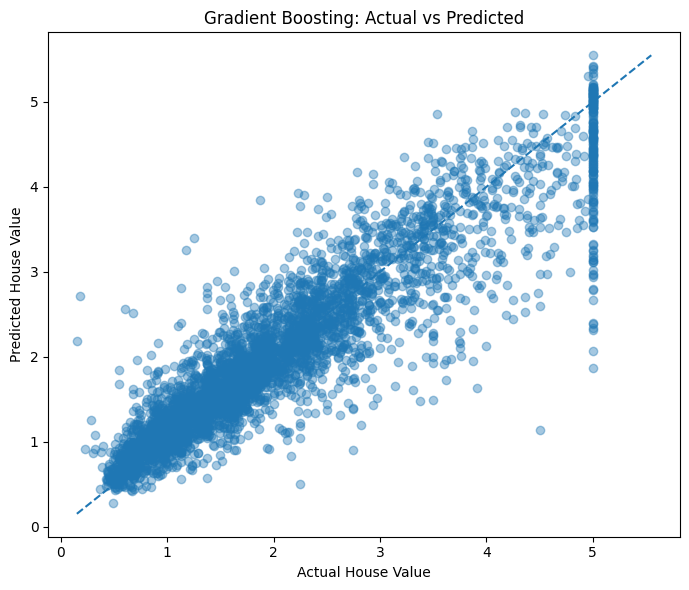

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_gbr
})

comparison["Error"] = (
    comparison["Actual"] - comparison["Predicted"]
)

comparison["Absolute_Error"] = comparison["Error"].abs()

print("Sample predictions:")
print(comparison.head(10).round(3))

print("\n10 worst predictions:")
print(
    comparison.nlargest(10, "Absolute_Error").round(3)
)

plt.figure(figsize=(7, 6))
plt.scatter(comparison["Actual"], comparison["Predicted"], alpha=0.4)

low = min(comparison["Actual"].min(), comparison["Predicted"].min())
high = max(comparison["Actual"].max(), comparison["Predicted"].max())

plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Gradient Boosting: Actual vs Predicted")
plt.tight_layout()
plt.show()

#TUNING GRADIENT BOOSTING




In [17]:
#hyper parametric tuning
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GridSearchCV

param_grid = {
    "learning_rate": [0.03, 0.05, 0.1],
    "max_iter": [100, 200, 300],
    "max_leaf_nodes": [15, 31, 50],
    "l2_regularization": [0, 1, 5]
}

grid = GridSearchCV(
    HistGradientBoostingRegressor(random_state=42),
    param_grid,
    cv=3,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV MAE:", -grid.best_score_)

Best parameters: {'l2_regularization': 0, 'learning_rate': 0.05, 'max_iter': 300, 'max_leaf_nodes': 50}
Best CV MAE: 0.30474989834951827


In [20]:
# Actual vs Predicted House Prices
import pandas as pd

# Get the best model found during hyperparameter tuning
best_model = grid.best_estimator_

# Generate predictions
y_pred_tuned = best_model.predict(X_test)

# Compare the first 10 predictions
comparison = pd.DataFrame({
    "Actual Price": y_test.values[:10],
    "Predicted Price": y_pred_tuned[:10]
})

comparison["Actual ($)"] = comparison["Actual Price"] * 100000
comparison["Predicted ($)"] = comparison["Predicted Price"] * 100000

display(comparison.round(2))

,Actual Price,Predicted Price,Actual ($),Predicted ($)
0,0.48,0.55,47700.0,55080.07
1,0.46,0.87,45800.0,87305.24
2,5.00,4.96,500001.0,496206.89
3,2.19,2.44,218600.0,244219.57
4,2.78,2.53,278000.0,253296.33
5,1.59,1.66,158700.0,166455.15
6,1.98,2.23,198200.0,223164.25
7,1.58,1.62,157500.0,161851.91
8,3.40,2.71,340000.0,270758.77
9,4.47,4.87,446600.0,486858.07


In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Tuned model performance")
print("MAE:", mean_absolute_error(y_test, y_pred_tuned))
print("RMSE:", mean_squared_error(y_test, y_pred_tuned) ** 0.5)
print("R²:", r2_score(y_test, y_pred_tuned))

Tuned model performance
MAE: 0.29401541406821075
RMSE: 0.44896244109608235
R²: 0.8461798744804555


In [22]:
# Worst predictions from the TUNED model
import pandas as pd

comparison_tuned = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_tuned
})

comparison_tuned["Error"] = (
    comparison_tuned["Actual"] - comparison_tuned["Predicted"]
)

comparison_tuned["Absolute_Error"] = (
    comparison_tuned["Error"].abs()
)

print("10 worst predictions from tuned model:")
display(
    comparison_tuned
    .nlargest(10, "Absolute_Error")
    .round(3)
)


10 worst predictions from tuned model:


,Actual,Predicted,Error,Absolute_Error
12389,5.000,1.381,3.619,3.619
19542,4.500,1.254,3.246,3.246
6688,5.000,1.887,3.113,3.113
12069,5.000,2.350,2.650,2.650
5887,0.175,2.770,-2.595,2.595
20325,5.000,2.435,2.565,2.565
14463,5.000,2.596,2.404,2.404
15652,5.000,2.751,2.249,2.249
20349,1.250,3.467,-2.217,2.217
459,5.000,2.788,2.212,2.212


In [23]:
# User Input Inference — Best Tuned Model

import pandas as pd

print("Enter the house details:")

MedInc = float(input("Median Income (in $10,000s): "))
HouseAge = float(input("House Age (years): "))
AveRooms = float(input("Average Rooms: "))
AveBedrms = float(input("Average Bedrooms: "))
Population = float(input("Population: "))
AveOccup = float(input("Average Occupants per Household: "))
Latitude = float(input("Latitude: "))
Longitude = float(input("Longitude: "))

# Create input DataFrame in the correct feature order
user_house = pd.DataFrame([{
    "MedInc": MedInc,
    "HouseAge": HouseAge,
    "AveRooms": AveRooms,
    "AveBedrms": AveBedrms,
    "Population": Population,
    "AveOccup": AveOccup,
    "Latitude": Latitude,
    "Longitude": Longitude
}])

# Predict using the best tuned model
predicted_price = best_model.predict(user_house)[0]

print("\n--- House Price Prediction ---")
print(f"Predicted Price: ${predicted_price * 100000:,.2f}")

if predicted_price >= 5.0:
    print("Note: The dataset caps target values around $500,000, so higher prices may not be estimated accurately.")

Enter the house details:
Median Income (in $10,000s): 2
House Age (years): 2
Average Rooms: 3
Average Bedrooms: 4
Population: 5
Average Occupants per Household: 1
Latitude: 34.05
Longitude: -118.24

--- House Price Prediction ---
Predicted Price: $275,985.24
